# GitHub Issue Classifier — Fine-tuning DeBERTa-v3 Small

**Model:** [`microsoft/deberta-v3-small`](https://huggingface.co/microsoft/deberta-v3-small)
**Task:** 6-class GitHub issue classification — `Bug`, `Feature Request`, `Documentation`, `Question`, `Performance`, `Security`
**Why this model:** Strong small encoder (~44M); needs sentencepiece; fp16 can be unstable.

This notebook fine-tunes **DeBERTa-v3 Small** on `data/train.csv` (3,541 labeled issues) with:

1. Stratified **80/20** train/test split (`random_state=42`)
2. Full fine-tune (no LoRA/PEFT), short schedule (~3 epochs)
3. Variants: **single**, **5-fold CV**, **bagging** (3 bootstraps), **boosting** (3 AdaBoost-style rounds)
4. Metrics + visuals: table, confusion matrices, OvR ROC / macro AUC, loss curves, variant bars

Artifacts (for `05_model_comparison_demo.ipynb`):

- `models/deberta_v3_small/` — best-variant model + tokenizer + label map
- `results/deberta_v3_small_metrics.json`
- `results/deberta_v3_small_probs.npy` — softmax probs of best variant on the shared test set
- `results/test_labels.npy` — shared test labels (same across notebooks 01–04)

**Runtime:** GPU (T4) recommended. Mount Drive so models/results persist.


In [1]:
!pip install -q -U transformers datasets accelerate evaluate scikit-learn seaborn sentencepiece


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 39.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 36.5 MB/s eta 0:00:00


In [2]:
import os
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    auc,
)
from sklearn.preprocessing import label_binarize
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    set_seed,
)

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())


Torch: 2.11.0+cu128 | CUDA available: True


## 1. Project folder

`PROJECT_DIR` defaults to Google Drive (`/content/drive/MyDrive/gitsort`).
If Drive is unavailable, falls back to `/content/gitsort` for the current session.


In [ ]:
import os
from pathlib import Path

# Colab Drive mount (skipped gracefully if running locally or not in Colab)
try:
    from google.colab import drive
    if not os.path.ismount('/content/drive'):
        drive.mount('/content/drive')
except (ImportError, Exception):
    pass

# Dynamic project root detection: Colab Drive, local parent directory (from notebooks/), or local repo root
if os.path.isdir("/content/drive/MyDrive/gitsort"):
    PROJECT_DIR = "/content/drive/MyDrive/gitsort"
elif os.path.isdir("../data"):
    PROJECT_DIR = ".."
elif os.path.isdir("./data"):
    PROJECT_DIR = "."
else:
    PROJECT_DIR = "/content/gitsort"
    os.makedirs(PROJECT_DIR, exist_ok=True)

DATA_DIR = f"{PROJECT_DIR}/data"
MODELS_DIR = f"{PROJECT_DIR}/models"
RESULTS_DIR = f"{PROJECT_DIR}/results"
for d in (DATA_DIR, MODELS_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

print("Project dir:", PROJECT_DIR)
print("Data dir:", DATA_DIR)

Mounted at /content/drive
Using already-mounted Drive path: /content/drive/MyDrive/nlp-project
Project dir: /content/drive/MyDrive/nlp-project
Data dir: /content/drive/MyDrive/nlp-project/data


## 2. Load `train.csv` and shared 80/20 split

Text = `title + " [SEP] " + description`. Labels come from `label_map.json`.
Split is identical in notebooks 01–04: `train_test_split(test_size=0.2, stratify=label, random_state=42)`.


In [4]:
with open(f"{DATA_DIR}/label_map.json") as f:
    label_maps = json.load(f)

LABEL2ID = {k: int(v) for k, v in label_maps["label2id"].items()}
ID2LABEL = {int(k): v for k, v in label_maps["id2label"].items()}
NUM_LABELS = len(LABEL2ID)
CLASS_NAMES = [ID2LABEL[i] for i in range(NUM_LABELS)]
print("Classes:", CLASS_NAMES)

# df = pd.read_csv(f"{DATA_DIR}/train.csv")
df = pd.read_csv(f"{DATA_DIR}/train.csv")
df["title"] = df["title"].fillna("").astype(str)
df["description"] = df["description"].fillna("").astype(str)
df["text"] = df["title"] + " [SEP] " + df["description"]
df["labels"] = df["label"].map(LABEL2ID)
assert df["labels"].isna().sum() == 0, "Unmapped labels present"

print("Rows:", len(df))
print("Class counts:\n", df["label"].value_counts().to_string())

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["label"],
    random_state=SEED,
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print(f"Train: {len(train_df)} | Test: {len(test_df)}")
print("Train counts:\n", train_df["label"].value_counts().to_string())
print("Test counts:\n", test_df["label"].value_counts().to_string())

# Shared test labels for notebook 05 (identical across 01-04)
test_labels = test_df["labels"].to_numpy(dtype=np.int64)
np.save(f"{RESULTS_DIR}/test_labels.npy", test_labels)
print("Saved", f"{RESULTS_DIR}/test_labels.npy", "shape", test_labels.shape)

MODEL_NAME = "microsoft/deberta-v3-small"
MODEL_KEY = "deberta_v3_small"
DISPLAY_NAME = "DeBERTa-v3 Small"
MAX_LEN = 256
N_EPOCHS = 3
LEARNING_RATE = 2e-05
TRAIN_BS = 8
EVAL_BS = TRAIN_BS * 2
N_BAGS = 3
N_BOOST = 3
N_FOLDS = 5
USE_FP16 = False
print("HF id:", MODEL_NAME, "| fp16:", USE_FP16)


Classes: ['Bug', 'Feature Request', 'Documentation', 'Question', 'Performance', 'Security']
Rows: 3541
Class counts:
 label
Bug                992
Feature Request    921
Documentation      685
Question           580
Performance        302
Security            61
Train: 2832 | Test: 709
Train counts:
 label
Bug                793
Feature Request    737
Documentation      548
Question           464
Performance        241
Security            49
Test counts:
 label
Bug                199
Feature Request    184
Documentation      137
Question           116
Performance         61
Security            12
Saved /content/drive/MyDrive/nlp-project/results/test_labels.npy shape (709,)
HF id: microsoft/deberta-v3-small | fp16: False


## 3. Helpers — tokenize, metrics, weighted trainer, predict


In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def make_dataset(frame: pd.DataFrame) -> Dataset:
    ds = Dataset.from_pandas(frame[["text", "labels"]].reset_index(drop=True), preserve_index=False)

    def _tok(batch):
        return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=MAX_LEN)

    ds = ds.map(_tok, batched=True)
    cols = ["input_ids", "attention_mask", "labels"]
    if "token_type_ids" in ds.column_names:
        cols.insert(2, "token_type_ids")
    ds.set_format(type="torch", columns=cols)
    return ds


def class_weight_tensor(labels_arr: np.ndarray) -> torch.Tensor:
    counts = np.bincount(labels_arr.astype(int), minlength=NUM_LABELS).astype(np.float64)
    counts = np.maximum(counts, 1.0)
    weights = counts.sum() / (NUM_LABELS * counts)
    return torch.tensor(weights, dtype=torch.float)


def metric_dict(y_true, y_pred, probs=None):
    acc = float(accuracy_score(y_true, y_pred))
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    out = {
        "accuracy": acc,
        "precision_macro": float(p),
        "recall_macro": float(r),
        "f1_macro": float(f1),
    }
    if probs is not None:
        y_bin = label_binarize(y_true, classes=list(range(NUM_LABELS)))
        try:
            out["auc_macro"] = float(
                roc_auc_score(y_bin, probs, average="macro", multi_class="ovr")
            )
        except ValueError:
            # Rare: a class missing from y_true (should not happen with stratified split)
            out["auc_macro"] = float("nan")
    return out


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": precision_recall_fscore_support(
            labels, preds, average="macro", zero_division=0
        )[2],
    }


class WeightedTrainer(Trainer):
    def __init__(self, class_weights=None, sample_weights=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
        self.sample_weights = sample_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        if self.sample_weights is not None:
            # per-example weights aligned to the *current batch indices* are not
            # available here; use class weights only. Boosting uses WeightedRandomSampler
            # via dataset resampling instead.
            weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
            loss_fct = torch.nn.CrossEntropyLoss(weight=weight)
            loss = loss_fct(logits, labels)
        else:
            weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
            loss_fct = torch.nn.CrossEntropyLoss(weight=weight)
            loss = loss_fct(logits, labels)
        return (loss, outputs) if return_outputs else loss


def build_model():
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=NUM_LABELS,
        id2label=ID2LABEL,
        label2id=LABEL2ID,
    )
    # Explicitly cast to float32 to prevent half-precision vs float mismatches
    return model.float()


def make_training_args(output_dir: str, epochs: int = N_EPOCHS, lr: float = LEARNING_RATE):
    return TrainingArguments(
        output_dir=output_dir,
        eval_strategy="epoch",
        save_strategy="epoch",
        learning_rate=lr,
        per_device_train_batch_size=TRAIN_BS,
        per_device_eval_batch_size=EVAL_BS,
        num_train_epochs=epochs,
        weight_decay=0.01,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        logging_strategy="epoch",
        save_total_limit=1,
        fp16=USE_FP16,
        report_to="none",
        seed=SEED,
        dataloader_drop_last=False,
    )


def train_one(train_frame: pd.DataFrame, eval_frame: pd.DataFrame, run_name: str, epochs: int = N_EPOCHS):
    train_ds = make_dataset(train_frame)
    eval_ds = make_dataset(eval_frame)
    cw = class_weight_tensor(train_frame["labels"].to_numpy())
    model = build_model()
    out_dir = f"{MODELS_DIR}/{MODEL_KEY}_runs/{run_name}"
    args = make_training_args(out_dir, epochs=epochs)
    trainer = WeightedTrainer(
        class_weights=cw,
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    train_result = trainer.train()
    history = trainer.state.log_history
    return trainer, model, history


def predict_proba(trainer: Trainer, frame: pd.DataFrame) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    ds = make_dataset(frame)
    pred = trainer.predict(ds)
    logits = pred.predictions
    # softmax
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    probs = e / e.sum(axis=1, keepdims=True)
    y_pred = probs.argmax(axis=1)
    y_true = np.asarray(pred.label_ids)
    return y_true, y_pred, probs


print("Helpers ready with float32 casting fixed.")

config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

Helpers ready with float32 casting fixed.


## 4. Variant A — Single fine-tune on full train set

Train on all 320 stratified train rows; evaluate on the held-out test set.
Also capture train/eval loss curves for the visuals section.


In [6]:
single_trainer, single_model, single_history = train_one(
    train_df, test_df, run_name="single", epochs=N_EPOCHS
)
y_true_s, y_pred_s, probs_s = predict_proba(single_trainer, test_df)
single_metrics = metric_dict(y_true_s, y_pred_s, probs_s)
print("Single metrics:", json.dumps(single_metrics, indent=2))
print(classification_report(y_true_s, y_pred_s, target_names=CLASS_NAMES, zero_division=0))

# Latency (ms / sample) on test set
_t0 = time.perf_counter()
_ = predict_proba(single_trainer, test_df)
_elapsed = time.perf_counter() - _t0
latency_ms_per_sample = 1000.0 * _elapsed / max(len(test_df), 1)
print(f"Test latency: {latency_ms_per_sample:.3f} ms/sample")

# Loss curves from log history
train_losses, eval_losses, epochs_logged = [], [], []
for row in single_history:
    if "loss" in row and "epoch" in row and "eval_loss" not in row:
        train_losses.append((row["epoch"], row["loss"]))
    if "eval_loss" in row and "epoch" in row:
        eval_losses.append((row["epoch"], row["eval_loss"]))
        epochs_logged.append(row["epoch"])


Map:   0%|          | 0/2832 [00:00<?, ? examples/s]

Map:   0%|          | 0/709 [00:00<?, ? examples/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  286MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
classifie

... (6 outputs left out)

Map:   0%|          | 0/709 [00:00<?, ? examples/s]

Single metrics: {
  "accuracy": 0.771509167842031,
  "precision_macro": 0.7159610888102931,
  "recall_macro": 0.7104309248513445,
  "f1_macro": 0.712590532954824,
  "auc_macro": 0.9269699946092745
}
                 precision    recall  f1-score   support

            Bug       0.76      0.81      0.79       199
Feature Request       0.86      0.79      0.83       184
  Documentation       0.86      0.84      0.85       137
       Question       0.60      0.61      0.60       116
    Performance       0.76      0.79      0.77        61
       Security       0.45      0.42      0.43        12

       accuracy                           0.77       709
      macro avg       0.72      0.71      0.71       709
   weighted avg       0.77      0.77      0.77       709



Map:   0%|          | 0/709 [00:00<?, ? examples/s]

Test latency: 14.471 ms/sample


## 5. Variant B — Stratified 5-fold CV (train only)

Reports mean ± std of fold validation metrics. Does not touch the held-out test set.


In [7]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_rows = []
cv_histories = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(train_df, train_df["labels"])):
    print(f"\n=== Fold {fold + 1}/{N_FOLDS} ===")
    tr_fold = train_df.iloc[tr_idx].reset_index(drop=True)
    va_fold = train_df.iloc[va_idx].reset_index(drop=True)
    # Security is rare (~18 in train) — verify each fold still has all classes in train split
    print("Fold train counts:", tr_fold["label"].value_counts().to_dict())
    trainer_f, _, hist_f = train_one(tr_fold, va_fold, run_name=f"cv_fold{fold}", epochs=N_EPOCHS)
    y_t, y_p, pr = predict_proba(trainer_f, va_fold)
    m = metric_dict(y_t, y_p, pr)
    m["fold"] = fold
    fold_rows.append(m)
    cv_histories.append(hist_f)
    # free GPU memory between folds
    del trainer_f
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

cv_df = pd.DataFrame(fold_rows)
cv_mean = {
    k: float(cv_df[k].mean())
    for k in ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro"]
}
cv_std = {
    k: float(cv_df[k].std(ddof=0))
    for k in ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro"]
}
print("CV mean:", json.dumps(cv_mean, indent=2))
print("CV std:", json.dumps(cv_std, indent=2))
print(cv_df.to_string(index=False))



=== Fold 1/5 ===
Fold train counts: {'Bug': 634, 'Feature Request': 590, 'Documentation': 438, 'Question': 371, 'Performance': 193, 'Security': 39}


Map:   0%|          | 0/2265 [00:00<?, ? examples/s]

Map:   0%|          | 0/567 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
classifie

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.574091,1.227787,0.691358,0.544853
2,1.049551,0.990855,0.719577,0.605063
3,0.795714,0.902185,0.747795,0.649841


... (41 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/566 [00:00<?, ? examples/s]

CV mean: {
  "accuracy": 0.7256255414088157,
  "precision_macro": 0.7386385503336971,
  "recall_macro": 0.6521556444195296,
  "f1_macro": 0.6641214386100982,
  "auc_macro": 0.9111255171215561
}
CV std: {
  "accuracy": 0.017407246581484247,
  "precision_macro": 0.04369176165400728,
  "recall_macro": 0.007232977979935544,
  "f1_macro": 0.0073709788640571134,
  "auc_macro": 0.01360693139960534
}
 accuracy  precision_macro  recall_macro  f1_macro  auc_macro  fold
 0.747795         0.779927      0.643110  0.649841   0.936618     0
 0.731922         0.787743      0.646696  0.670684   0.903851     1
 0.712014         0.684531      0.663406  0.668480   0.908961     2
 0.736749         0.690140      0.656790  0.665763   0.909785     3
 0.699647         0.750852      0.650776  0.665839   0.896413     4


## 6. Variant C — Bagging (3 bootstrap resamples)

Each bootstrap draws `len(train)` rows with replacement (stratified-ish via labels),
fine-tunes briefly, then soft-votes probability averages on the shared test set.


In [8]:
bag_probs = []
rng = np.random.RandomState(SEED)

for b in range(N_BAGS):
    print(f"\n=== Bag {b + 1}/{N_BAGS} ===")
    # Stratified bootstrap: resample within each class, then concat
    parts = []
    for lab, grp in train_df.groupby("labels"):
        idx = rng.choice(grp.index.to_numpy(), size=len(grp), replace=True)
        parts.append(train_df.loc[idx])
    boot = pd.concat(parts, ignore_index=True).sample(frac=1.0, random_state=SEED + b).reset_index(drop=True)
    # small held-out slice from original train for early stopping (~15%)
    boot_tr, boot_va = train_test_split(
        boot, test_size=0.15, stratify=boot["labels"], random_state=SEED + b
    )
    trainer_b, _, _ = train_one(
        boot_tr.reset_index(drop=True),
        boot_va.reset_index(drop=True),
        run_name=f"bag{b}",
        epochs=N_EPOCHS,
    )
    _, _, pr = predict_proba(trainer_b, test_df)
    bag_probs.append(pr)
    del trainer_b
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

probs_bag = np.mean(np.stack(bag_probs, axis=0), axis=0)
y_pred_bag = probs_bag.argmax(axis=1)
bagging_metrics = metric_dict(test_labels, y_pred_bag, probs_bag)
print("Bagging metrics:", json.dumps(bagging_metrics, indent=2))



=== Bag 1/3 ===


Map:   0%|          | 0/2407 [00:00<?, ? examples/s]

Map:   0%|          | 0/425 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
classifie

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.550083,1.104905,0.694118,0.588670
2,0.896760,0.863914,0.734118,0.630473


... (22 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/709 [00:00<?, ? examples/s]

Bagging metrics: {
  "accuracy": 0.7729196050775741,
  "precision_macro": 0.7659406592488255,
  "recall_macro": 0.6946724960526117,
  "f1_macro": 0.7084245419740283,
  "auc_macro": 0.9350530664714185
}


## 7. Variant D — Boosting (3 AdaBoost-style rounds)

Reweight / resample misclassified train examples across rounds; soft-vote the round models on test.
Round weights follow AdaBoost multi-class (SAMME-style) confidence.


In [9]:
n_train = len(train_df)
sample_w = np.ones(n_train, dtype=np.float64) / n_train
boost_probs = []
boost_alphas = []

for t in range(N_BOOST):
    print(f"\n=== Boost round {t + 1}/{N_BOOST} ===")
    # Weighted resample of the train set
    idx = rng.choice(np.arange(n_train), size=n_train, replace=True, p=sample_w)
    round_df = train_df.iloc[idx].reset_index(drop=True)
    # tiny validation from original train distribution for early stopping
    _, va_idx = next(
        StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + t).split(
            train_df, train_df["labels"]
        )
    )
    va_df = train_df.iloc[va_idx].reset_index(drop=True)
    trainer_t, _, _ = train_one(round_df, va_df, run_name=f"boost{t}", epochs=N_EPOCHS)

    # Error on full train set to update weights
    y_tr, y_hat, pr_tr = predict_proba(trainer_t, train_df)
    incorrect = (y_hat != y_tr).astype(np.float64)
    err = float(np.clip((sample_w * incorrect).sum(), 1e-6, 1 - 1e-6))
    # SAMME alpha
    K = NUM_LABELS
    alpha = np.log((1.0 - err) / err) + np.log(K - 1.0)
    alpha = float(max(alpha, 1e-3))
    boost_alphas.append(alpha)
    sample_w = sample_w * np.exp(alpha * incorrect)
    sample_w = sample_w / sample_w.sum()

    _, _, pr_te = predict_proba(trainer_t, test_df)
    boost_probs.append(pr_te)
    print(f"round err={err:.4f} alpha={alpha:.4f}")
    del trainer_t
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

alphas = np.asarray(boost_alphas, dtype=np.float64)
alphas = alphas / alphas.sum()
probs_boost = np.tensordot(alphas, np.stack(boost_probs, axis=0), axes=(0, 0))
y_pred_boost = probs_boost.argmax(axis=1)
boosting_metrics = metric_dict(test_labels, y_pred_boost, probs_boost)
print("Boosting metrics:", json.dumps(boosting_metrics, indent=2))
print("Round alphas (normalized):", alphas.tolist())



=== Boost round 1/3 ===


Map:   0%|          | 0/2832 [00:00<?, ? examples/s]

Map:   0%|          | 0/567 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
classifie

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.466709,1.063910,0.717813,0.597754
2,0.888075,0.829389,0.798942,0.723644
3,0.669830,0.741807,0.827160,0.780750


... (24 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Map:   0%|          | 0/2832 [00:00<?, ? examples/s]

Map:   0%|          | 0/709 [00:00<?, ? examples/s]

round err=0.1520 alpha=3.3284
Boosting metrics: {
  "accuracy": 0.7433004231311706,
  "precision_macro": 0.7577854969556946,
  "recall_macro": 0.7098687834405908,
  "f1_macro": 0.7247773796203706,
  "auc_macro": 0.9333686775609896
}
Round alphas (normalized): [0.3095429082177459, 0.3405467646857034, 0.3499103270965507]


## 8. Pick best variant, save model / metrics / probs

Best among **single / bagging / boosting** by `f1_macro` on the shared test set.
(CV is reported for stability only — it has no single test probability vector.)


In [12]:
variant_scores = {
    "single": single_metrics,
    "bagging": bagging_metrics,
    "boosting": boosting_metrics,
}
best_variant = max(variant_scores, key=lambda k: variant_scores[k]["f1_macro"])
print("Best variant:", best_variant, variant_scores[best_variant])

if best_variant == "single":
    best_probs = probs_s
    best_pred = y_pred_s
    # re-save the already-trained single model
    final_dir = f"{MODELS_DIR}/{MODEL_KEY}"
    single_trainer.save_model(final_dir)
    tokenizer.save_pretrained(final_dir)
elif best_variant == "bagging":
    best_probs = probs_bag
    best_pred = y_pred_bag
    # Retrain one full-data model as the shipped artifact (bagging is an ensemble of probs)
    ship_trainer, _, _ = train_one(train_df, test_df, run_name="ship_bagging_refit", epochs=N_EPOCHS)
    final_dir = f"{MODELS_DIR}/{MODEL_KEY}"
    ship_trainer.save_model(final_dir)
    tokenizer.save_pretrained(final_dir)
else:
    best_probs = probs_boost
    best_pred = y_pred_boost
    ship_trainer, _, _ = train_one(train_df, test_df, run_name="ship_boost_refit", epochs=N_EPOCHS)
    final_dir = f"{MODELS_DIR}/{MODEL_KEY}"
    ship_trainer.save_model(final_dir)
    tokenizer.save_pretrained(final_dir)

# Persist label map next to the model
with open(f"{final_dir}/label_map.json", "w") as f:
    json.dump({"label2id": LABEL2ID, "id2label": {str(k): v for k, v in ID2LABEL.items()}}, f, indent=2)

params = int(sum(p.numel() for p in single_model.parameters()))

metrics_record = {
    "model": MODEL_KEY,
    "hf_id": MODEL_NAME,
    "params": params,
    "best_variant": best_variant,
    "single": single_metrics,
    "cv_mean": cv_mean,
    "cv_std": cv_std,
    "bagging": bagging_metrics,
    "boosting": boosting_metrics,
    "latency_ms_per_sample": float(latency_ms_per_sample),
    "n_train": int(len(train_df)),
    "n_test": int(len(test_df)),
    "epochs": int(N_EPOCHS),
    "max_len": int(MAX_LEN),
    "fp16": bool(USE_FP16),
}
with open(f"{RESULTS_DIR}/{MODEL_KEY}_metrics.json", "w") as f:
    json.dump(metrics_record, f, indent=2)

assert best_probs.shape == (len(test_df), NUM_LABELS)
np.save(f"{RESULTS_DIR}/{MODEL_KEY}_probs.npy", best_probs.astype(np.float32))
print("Saved model ->", final_dir)
print("Saved metrics ->", f"{RESULTS_DIR}/{MODEL_KEY}_metrics.json")
print("Saved probs ->", f"{RESULTS_DIR}/{MODEL_KEY}_probs.npy", best_probs.shape)
print(json.dumps(metrics_record, indent=2))


Best variant: boosting {'accuracy': 0.7433004231311706, 'precision_macro': 0.7577854969556946, 'recall_macro': 0.7098687834405908, 'f1_macro': 0.7247773796203706, 'auc_macro': 0.9333686775609896}


Map:   0%|          | 0/2832 [00:00<?, ? examples/s]

Map:   0%|          | 0/709 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
classifie

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.705125,1.500915,0.557123,0.427372
2,1.143083,0.940717,0.764457,0.666307
3,0.838913,0.930619,0.770099,0.687228


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model -> /content/drive/MyDrive/nlp-project/models/deberta_v3_small
Saved metrics -> /content/drive/MyDrive/nlp-project/results/deberta_v3_small_metrics.json
Saved probs -> /content/drive/MyDrive/nlp-project/results/deberta_v3_small_probs.npy (709, 6)
{
  "model": "deberta_v3_small",
  "hf_id": "microsoft/deberta-v3-small",
  "params": 141899526,
  "best_variant": "boosting",
  "single": {
    "accuracy": 0.771509167842031,
    "precision_macro": 0.7159610888102931,
    "recall_macro": 0.7104309248513445,
    "f1_macro": 0.712590532954824,
    "auc_macro": 0.9269699946092745
  },
  "cv_mean": {
    "accuracy": 0.7256255414088157,
    "precision_macro": 0.7386385503336971,
    "recall_macro": 0.6521556444195296,
    "f1_macro": 0.6641214386100982,
    "auc_macro": 0.9111255171215561
  },
  "cv_std": {
    "accuracy": 0.017407246581484247,
    "precision_macro": 0.04369176165400728,
    "recall_macro": 0.007232977979935544,
    "f1_macro": 0.0073709788640571134,
    "auc_macro": 0.

## 9. Visuals — metrics table, confusion matrices, ROC, loss, variant bars


          accuracy  precision_macro  recall_macro  f1_macro  auc_macro
variant                                                               
single      0.7715           0.7160        0.7104    0.7126     0.9270
bagging     0.7729           0.7659        0.6947    0.7084     0.9351
boosting    0.7433           0.7578        0.7099    0.7248     0.9334
cv_mean     0.7256           0.7386        0.6522    0.6641     0.9111


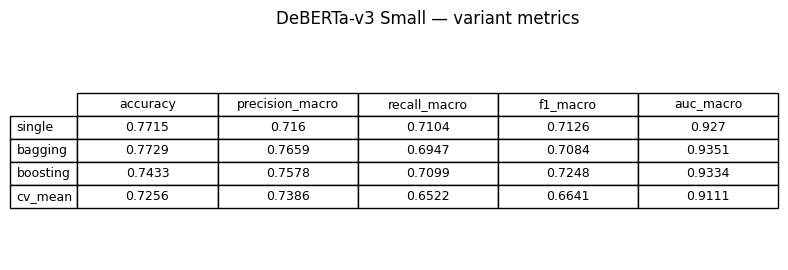

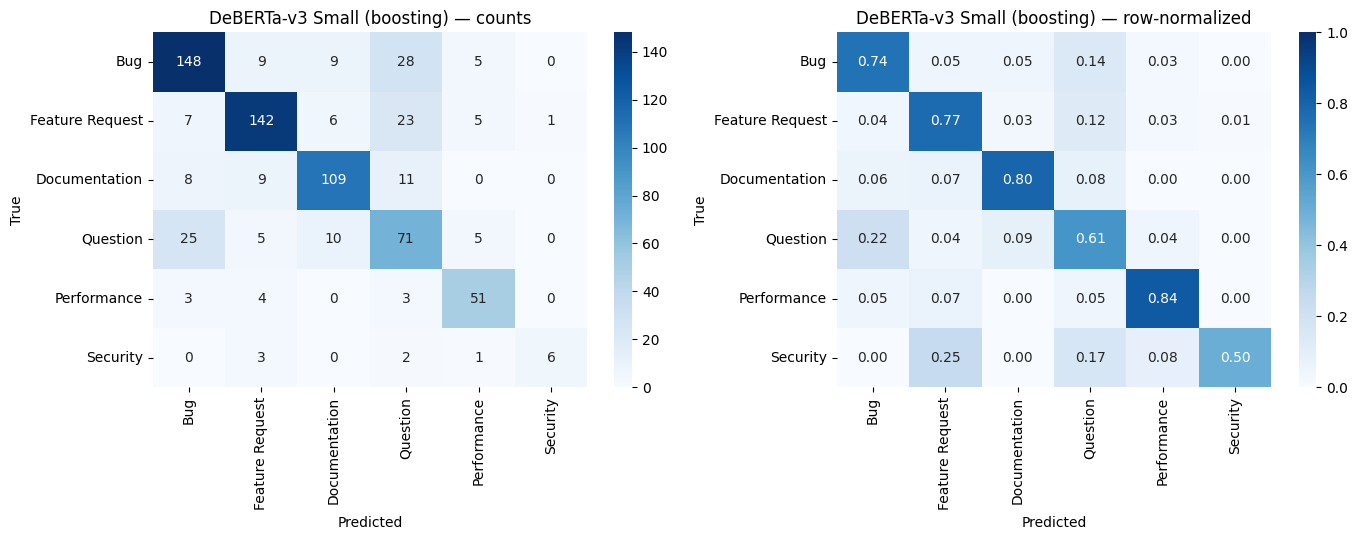

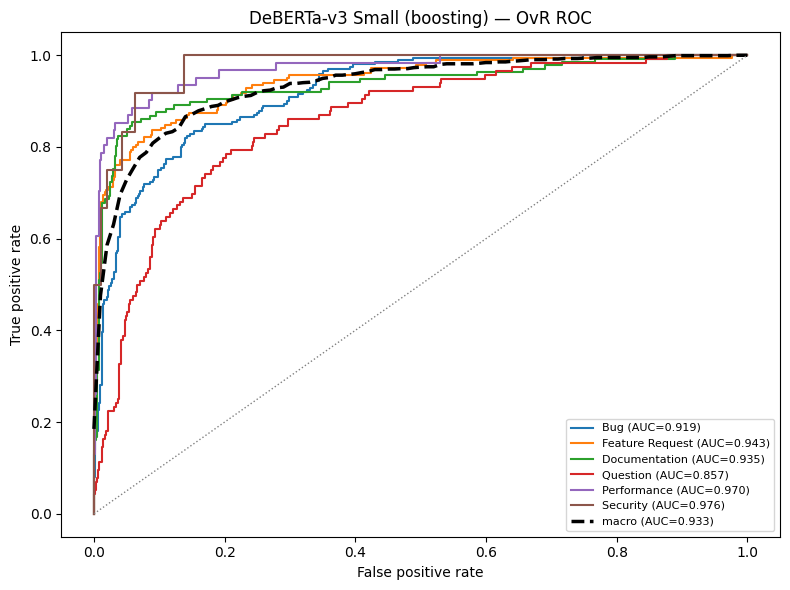

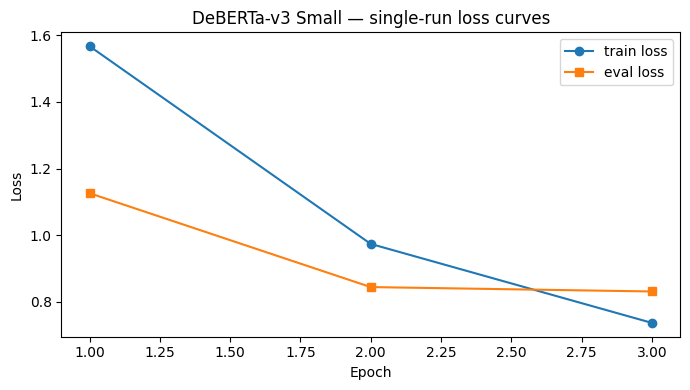

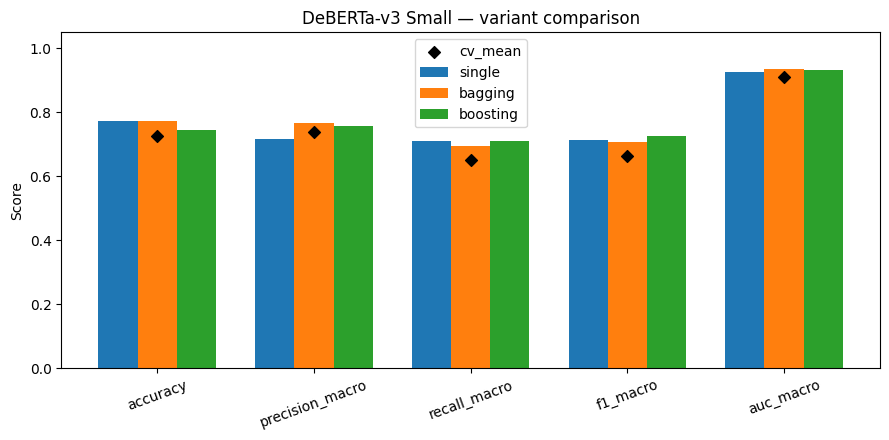

Figures written under /content/drive/MyDrive/nlp-project/results


In [13]:
# --- Metrics comparison table ---
rows = []
for name, m in [
    ("single", single_metrics),
    ("bagging", bagging_metrics),
    ("boosting", boosting_metrics),
]:
    rows.append({"variant": name, **m})
rows.append({"variant": "cv_mean", **cv_mean})
metrics_table = pd.DataFrame(rows).set_index("variant")
print(metrics_table.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.axis("off")
tbl = ax.table(
    cellText=np.round(metrics_table.values, 4),
    rowLabels=list(metrics_table.index),
    colLabels=list(metrics_table.columns),
    loc="center",
    cellLoc="center",
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.15, 1.35)
ax.set_title(f"{DISPLAY_NAME} — variant metrics", pad=12)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/{MODEL_KEY}_metrics_table.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Confusion matrices (counts + normalized) for best variant ---
cm = confusion_matrix(test_labels, best_pred, labels=list(range(NUM_LABELS)))
cm_norm = cm.astype(np.float64) / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
)
axes[0].set_title(f"{DISPLAY_NAME} ({best_variant}) — counts")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
sns.heatmap(
    cm_norm, annot=True, fmt=".2f", cmap="Blues", ax=axes[1],
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0, vmax=1,
)
axes[1].set_title(f"{DISPLAY_NAME} ({best_variant}) — row-normalized")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/{MODEL_KEY}_confusion_matrix.png", dpi=150)
plt.show()

# --- OvR ROC curves + macro AUC ---
y_bin = label_binarize(test_labels, classes=list(range(NUM_LABELS)))
fig, ax = plt.subplots(figsize=(8, 6))
fpr_grid = np.linspace(0, 1, 101)
mean_tpr = np.zeros_like(fpr_grid)
for i, name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], best_probs[:, i])
    score = auc(fpr, tpr)
    ax.plot(fpr, tpr, lw=1.5, label=f"{name} (AUC={score:.3f})")
    mean_tpr += np.interp(fpr_grid, fpr, tpr)
mean_tpr /= NUM_LABELS
macro_auc = auc(fpr_grid, mean_tpr)
ax.plot(fpr_grid, mean_tpr, color="black", lw=2.5, linestyle="--", label=f"macro (AUC={macro_auc:.3f})")
ax.plot([0, 1], [0, 1], color="gray", lw=1, linestyle=":")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title(f"{DISPLAY_NAME} ({best_variant}) — OvR ROC")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/{MODEL_KEY}_roc.png", dpi=150)
plt.show()

# --- Loss curves (single run) ---
fig, ax = plt.subplots(figsize=(7, 4))
if train_losses:
    ax.plot([e for e, _ in train_losses], [v for _, v in train_losses], marker="o", label="train loss")
if eval_losses:
    ax.plot([e for e, _ in eval_losses], [v for _, v in eval_losses], marker="s", label="eval loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title(f"{DISPLAY_NAME} — single-run loss curves")
ax.legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/{MODEL_KEY}_loss_curves.png", dpi=150)
plt.show()

# --- Variant comparison bars ---
plot_variants = ["single", "bagging", "boosting"]
keys = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro"]
x = np.arange(len(keys))
width = 0.25
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, vname in enumerate(plot_variants):
    vals = [variant_scores[vname].get(k, np.nan) for k in keys]
    ax.bar(x + (i - 1) * width, vals, width, label=vname)
# CV mean as markers
ax.scatter(x, [cv_mean.get(k, np.nan) for k in keys], color="black", zorder=5, label="cv_mean", marker="D")
ax.set_xticks(x)
ax.set_xticklabels(keys, rotation=20)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title(f"{DISPLAY_NAME} — variant comparison")
ax.legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/{MODEL_KEY}_variant_bars.png", dpi=150)
plt.show()

print("Figures written under", RESULTS_DIR)


## Done

`DeBERTa-v3 Small` (`deberta_v3_small`) is fine-tuned with single / CV / bagging / boosting variants.
Best variant artifacts are in `models/deberta_v3_small/` and `results/deberta_v3_small_*`.

After notebooks 01–04 finish, open **`05_model_comparison_demo.ipynb`**.
